# Mouse only-growth training

Train the only-growth model used by the Mouse growth-rate panels.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import compute_uot_plans
import math


# Compute WFR semi-couplings between two snapshots.
def compute_exact_wfr_semi_coupling(X0, X1, delta):


    _, gamma0s, gamma1s, _ = compute_uot_plans([X0, X1], [0, 1], delta, False, cuda=torch.cuda.is_available())

    Gamma1_exact = gamma0s[0]
    Gamma2_exact = gamma1s[0]
    return torch.from_numpy(Gamma1_exact), torch.from_numpy(Gamma2_exact)

# Parameterize the single-particle position and mass path.
class RUOT_TrajectoryNet(nn.Module):
    def __init__(self, hidden_dim=256):
        super().__init__()


        self.net = nn.Sequential(
            nn.Linear(3, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, 2)
        )

    def forward(self, d, m, t):


        log_m = torch.log(m + 1e-12)


        features = torch.stack([d, log_m, t], dim=-1)
        out = self.net(features)

        net_m = out[..., 0]
        net_x = out[..., 1]


        m_t = (m ** t) * torch.exp(t * (1 - t) * net_m)


        x_t = d * (t + t * (1 - t) * net_x)

        return m_t, x_t


import math

def compute_action_loss(model, Psi_func, batch_size, device):


    steps = int(math.sqrt(batch_size))


    d_axis = torch.linspace(0.1, 6.1, steps, device=device)
    m_axis = torch.linspace(0.01, 10.1, steps, device=device)


    D_grid, M_grid = torch.meshgrid(d_axis, m_axis, indexing='ij')


    d = D_grid.reshape(-1)
    m = M_grid.reshape(-1)


    actual_batch = d.shape[0]


    t = torch.rand(actual_batch, device=device).requires_grad_(True)


    m_t, x_t = model(d, m, t)


    m_dot = torch.autograd.grad(
        outputs=m_t,
        inputs=t,
        grad_outputs=torch.ones_like(m_t),
        create_graph=True,
        retain_graph=True
    )[0]

    x_dot = torch.autograd.grad(
        outputs=x_t,
        inputs=t,
        grad_outputs=torch.ones_like(x_t),
        create_graph=True,
        retain_graph=True
    )[0]


    m_t_safe = torch.clamp(m_t, min=1e-6)

    kinetic_term = x_dot ** 2
    mass_penalty_term = Psi_func(m_dot / m_t_safe)

    action_density = 0.5 * (kinetic_term + mass_penalty_term) * m_t


    return action_density.mean()


def train_ruot_pinn(model_class, Psi_func, epochs=5000, batch_size=1024, lr=2e-3, device='cuda'):

    model = model_class().to(device)


    optimizer = optim.Adam(model.parameters(), lr=lr)

    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)

    model.train()
    print(f"🚀 Starting PINN Training on {device} (Batch={batch_size})")

    for epoch in range(1, epochs + 1):
        optimizer.zero_grad()


        loss = compute_action_loss(model, Psi_func, batch_size, device)


        loss.backward()


        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()
        scheduler.step()


        if epoch % 500 == 0 or epoch == 1:
            current_lr = scheduler.get_last_lr()[0]
            print(f"Epoch [{epoch:4d}/{epochs}] | Action Loss: {loss.item():.6e} | LR: {current_lr:.2e}")

    print("✅ Training Complete! The neural surrogate now approximates the optimal trajectory.")
    model.eval()
    return model


# Approximate the symmetric dynamic transport cost.
class RUOT_SymmetricModel(nn.Module):
    def __init__(self, hidden_dim=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, 1)
        )

    def forward_old(self, d, ratio):


        u = torch.abs(torch.log(ratio + 1e-12))


        u = torch.clamp(u, max=4.6)


        features = torch.stack([d, u], dim=-1)


        out = self.net(features).squeeze(-1)


        S = F.softplus(out) + 1e-4


        f_ratio = torch.sqrt(ratio + 1e-12) * S

        return f_ratio

    def forward(self, d, ratio):


        u = torch.log(ratio + 1e-12)


        u = torch.clamp(u, min=-15.0, max=15.0)

        features = torch.stack([d, u], dim=-1)


        out = self.net(features).squeeze(-1)


        N = F.softplus(out) + 1e-4


        f_ratio = (1.0 + ratio) * N

        return f_ratio


model = RUOT_SymmetricModel(hidden_dim=256)


def C_approx(x0, x1, m0, m1, model):
    d = torch.norm(x1 - x0, p=2, dim=-1)


    ratio = m1 / torch.clamp(m0, min=1e-8)


    return m0 * model(d, ratio)


def compute_trajectory_cost(trajectory_model, Psi_func, d_batch, m0_batch, m1_batch, steps=50):
    B = d_batch.shape[0]
    device = d_batch.device

    ratio = m1_batch / m0_batch

    t_1d = torch.linspace(0, 1, steps, device=device)
    t_grid = t_1d.view(1, steps).expand(B, steps)

    d_flat = d_batch.view(B, 1).expand(B, steps).reshape(-1)
    ratio_flat = ratio.view(B, 1).expand(B, steps).reshape(-1)

    t_flat = t_grid.reshape(-1).clone().requires_grad_(True)

    with torch.set_grad_enabled(True):
        m_t, x_t = trajectory_model(d_flat, ratio_flat, t_flat)


        m_dot = torch.autograd.grad(
            outputs=m_t, inputs=t_flat,
            grad_outputs=torch.ones_like(m_t),
            create_graph=False,
            retain_graph=True
        )[0]


        x_dot = torch.autograd.grad(
            outputs=x_t, inputs=t_flat,
            grad_outputs=torch.ones_like(x_t),
            create_graph=False,
            retain_graph=False
        )[0]

    m_t_safe = torch.clamp(m_t, min=1e-8)
    kinetic = x_dot ** 2
    penalty = Psi_func(m_dot / m_t_safe)

    L_flat = 0.5 * (kinetic + penalty) * m_t
    L_grid = L_flat.view(B, steps)

    cost_base = torch.trapz(L_grid, t_grid, dim=1)

    return m0_batch * cost_base


def train_neural_cost_surrogate_multitime(Xs, trajectory_model, Psi_func, epochs=2000, batch_size=1000, lr=1e-3, device='cuda'):


    model = RUOT_SymmetricModel(hidden_dim=256).to(device)

    trajectory_model = trajectory_model.to(device)
    trajectory_model.eval()


    dim = Xs[0].shape[1]


    grid_steps = int(round(batch_size ** (1.0 / 2.0)))
    actual_batch = grid_steps ** 2

    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)


    loss_fn = nn.SmoothL1Loss(beta=1.0)
    model.train()

    print(f"🚀 Starting Physics-Grid Distillation!")
    print(f"Grid shape: {grid_steps}x{grid_steps} = {actual_batch} points per epoch")

    for epoch in range(1, epochs + 1):


        d_min, d_max = 0.01, 6.0
        m0_min, m0_max = 1.0, 1.0
        ratio_min, ratio_max = 0.01, 10.0


        d_axis = torch.linspace(d_min, d_max, grid_steps, device=device) + (torch.rand(1, device=device)*0.01)
        ratio_axis = torch.logspace(math.log(ratio_min), math.log(ratio_max), grid_steps, device=device) + (torch.rand(1, device=device)*0.01)


        D_grid, R_grid = torch.meshgrid(d_axis, ratio_axis, indexing='ij')


        d_batch = D_grid.reshape(-1)
        m0_batch = torch.ones_like(d_batch) * m0_min
        ratio_batch = R_grid.reshape(-1)

        m1_batch = m0_batch * ratio_batch


        x0_batch = torch.zeros((actual_batch, dim), device=device)
        x1_batch = torch.zeros((actual_batch, dim), device=device)
        x1_batch[:, 0] = d_batch


        with torch.no_grad():
            true_cost = compute_trajectory_cost(
                trajectory_model,
                Psi_func,
                d_batch,
                m0_batch,
                m1_batch,
                steps=50
            ).detach()


        approx_cost = C_approx(x0_batch, x1_batch, m0_batch, m1_batch, model)


        loss = loss_fn(approx_cost, true_cost)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()


        if epoch % 200 == 0 or epoch == 1:
            print(f"Epoch [{epoch:4d}/{epochs}] | Loss: {loss.item():.6e}")

    print("✅ Physics-Grid Distillation Complete! The fast surrogate is universal now.")
    model.eval()
    return model


def project_simplex(v, dim=1):


    sorted_v, _ = torch.sort(v, descending=True, dim=dim)


    cssv = torch.cumsum(sorted_v, dim=dim)


    N = v.shape[dim]
    indices = torch.arange(1, N + 1, device=v.device, dtype=v.dtype)
    shape = [1] * v.ndim
    shape[dim] = N
    indices = indices.view(shape)


    cond_mask = sorted_v - (cssv - 1.0) / indices > 0.0


    rho = cond_mask.sum(dim=dim, keepdim=True)


    rho_idx = (rho - 1).clamp(min=0).to(torch.long)
    cssv_idx = torch.gather(cssv, dim, rho_idx)


    tau = (cssv_idx - 1.0) / rho.to(v.dtype)


    return torch.clamp(v - tau, min=0.0)


def compute_custom_cost(X0, X1, Gamma1, Gamma2, cost_model):
    d = torch.cdist(X0, X1, p=2).to(torch.float32)


    eps = 1e-5
    Gamma1_safe = Gamma1 + eps
    Gamma2_safe = Gamma2 + eps

    ratio = Gamma2_safe / Gamma1_safe
    cost = Gamma1_safe * cost_model(d, ratio)

    return cost


def compute_approx_semi_coupling_PGD(X0, X1, cost_model, lr=0.01, num_iters=50):


    B1 = X0.shape[0]
    B2 = X1.shape[0]


    Gamma1 = torch.ones((B1, B2), device=X0.device, dtype=torch.float32) / B2
    Gamma2 = torch.ones((B1, B2), device=X0.device, dtype=torch.float32) / B1
    for step in range(num_iters):


        Gamma1 = Gamma1.detach().requires_grad_(True)
        cost = compute_custom_cost(X0, X1, Gamma1, Gamma2, cost_model)


        C1 = torch.autograd.grad(cost.sum(), Gamma1)[0]

        with torch.no_grad():

            V1 = Gamma1 - lr * C1


            Gamma1 = project_simplex(V1, dim=1)


        Gamma2 = Gamma2.detach().requires_grad_(True)
        cost = compute_custom_cost(X0, X1, Gamma1, Gamma2, cost_model)

        C2 = torch.autograd.grad(cost.sum(), Gamma2)[0]

        with torch.no_grad():

            V2 = Gamma2 - lr * C2

            Gamma2 = project_simplex(V2, dim=0)

        if step%10 == 0:
            print(step)
    return Gamma1, Gamma2

def compute_approx_semi_coupling_Joint_PGD(X0, X1, cost_model, initial_lr=0.05, num_iters=500):


    B1, B2 = X0.shape[0], X1.shape[0]
    Gamma1 = torch.ones((B1, B2), device=X0.device) / B2
    Gamma2 = torch.ones((B1, B2), device=X0.device) / B1

    for step in range(num_iters):

        lr = initial_lr * (0.999 ** step)
        Gamma1 = Gamma1.detach().requires_grad_(True)
        Gamma2 = Gamma2.detach().requires_grad_(True)

        cost = compute_custom_cost(X0, X1, Gamma1, Gamma2, cost_model)
        C1, C2 = torch.autograd.grad(cost.sum(), [Gamma1, Gamma2])


        clip_val = 5.0
        C1 = torch.clamp(C1, min=-clip_val, max=clip_val)
        C2 = torch.clamp(C2, min=-clip_val, max=clip_val)

        with torch.no_grad():

            V1 = Gamma1 - lr * C1
            V2 = Gamma2 - lr * C2


            Gamma1 = project_simplex(V1, dim=1)
            Gamma2 = project_simplex(V2, dim=0)

        if step % 50 == 0:
            print(f"Step {step:3d} | Approx Cost: {cost.sum().item():.4f}")

    return Gamma1, Gamma2

# Optimize the two semi-couplings with entropic projected gradients.
def compute_approx_semi_coupling_Entropic_PGD(X0, X1, cost_model, delta, epsilon=0.05, initial_lr=0.05, num_iters=200, use_mini_batch=True, chunk_size=1024):


    device = X0.device
    B1, B2 = X0.shape[0], X1.shape[0]


    def run_pgd_core(x0_b, x1_b, chunk_info="Full-Batch"):
        b1_size, b2_size = x0_b.shape[0], x1_b.shape[0]
        print(f"     [{chunk_info}] Start optimization for shape ({b1_size}x{b2_size})")


        with torch.no_grad():

            print(f"     [{chunk_info}] Computing exact WFR semi-coupling as initialization...")


            x0_cpu = x0_b.detach().cpu().numpy()
            x1_cpu = x1_b.detach().cpu().numpy()


            Gamma1_b, Gamma2_b = compute_exact_wfr_semi_coupling(x0_cpu, x1_cpu, delta=delta)


            Gamma1_b = torch.tensor(Gamma1_b, dtype=torch.float32, device=device)
            Gamma2_b = torch.tensor(Gamma2_b, dtype=torch.float32, device=device)


        print(f"     [{chunk_info}] Starting Entropic PGD loop ({num_iters} iters)...")

        print_step = max(1, num_iters // 10)

        for step in range(num_iters):
            lr = initial_lr * (0.999 ** step)

            Gamma1_b = Gamma1_b.detach().requires_grad_(True)
            Gamma2_b = Gamma2_b.detach().requires_grad_(True)


            cost = compute_custom_cost(x0_b, x1_b, Gamma1_b, Gamma2_b, cost_model)


            entropy1 = (Gamma1_b * torch.log(Gamma1_b + 1e-8)).sum()
            entropy2 = (Gamma2_b * torch.log(Gamma2_b + 1e-8)).sum()

            total_loss = cost.sum() + epsilon * (entropy1 + entropy2)


            C1, C2 = torch.autograd.grad(total_loss, [Gamma1_b, Gamma2_b])
            clip_val = 10.0
            C1 = torch.clamp(C1, min=-clip_val, max=clip_val)
            C2 = torch.clamp(C2, min=-clip_val, max=clip_val)

            with torch.no_grad():
                V1 = Gamma1_b - lr * C1
                V2 = Gamma2_b - lr * C2


                Gamma1_b = project_simplex(V1, dim=1)
                Gamma2_b = project_simplex(V2, dim=0)


            if step % print_step == 0 or step == num_iters - 1:
                print(f"       Step {step:3d}/{num_iters} | LR: {lr:.4f} | Total Loss: {total_loss.item():.4f} | Physics Cost: {cost.sum().item():.4f}")

        return Gamma1_b.detach(), Gamma2_b.detach(), total_loss.item(), cost.sum().item()


    print("\n" + "-" * 50)
    if not use_mini_batch:
        print(f"🚀 Running Full-Batch Entropic PGD (Shape: {B1} x {B2})")


        Gamma1_opt, Gamma2_opt, final_loss, final_cost = run_pgd_core(X0, X1, chunk_info="Full-Batch")
        return Gamma1_opt, Gamma2_opt

    else:

        Gamma1_global = torch.zeros((B1, B2), device=device)
        Gamma2_global = torch.zeros((B1, B2), device=device)


        perm1 = torch.randperm(B1, device=device)
        perm2 = torch.randperm(B2, device=device)


        num_batches = max(1, max(B1, B2) // chunk_size)
        if max(B1, B2) % chunk_size != 0:
            num_batches += 1

        print(f"🚀 Running Mini-Batch Entropic PGD | Total Shape: ({B1}x{B2}) | Chunks: {num_batches} | Max Chunk Size: {chunk_size}")


        for b in range(num_batches):
            print(f"\n   >>> Processing Chunk {b+1}/{num_batches}...")

            start_1 = int(b * (B1 / num_batches))
            end_1 = int((b + 1) * (B1 / num_batches))
            start_2 = int(b * (B2 / num_batches))
            end_2 = int((b + 1) * (B2 / num_batches))

            idx1 = perm1[start_1:end_1]
            idx2 = perm2[start_2:end_2]

            x0_b = X0[idx1]
            x1_b = X1[idx2]


            chunk_name = f"Chunk {b+1}"
            G1_b, G2_b, b_loss, b_cost = run_pgd_core(x0_b, x1_b, chunk_info=chunk_name)

            print(f"   <<< Chunk {b+1} Finished | Final Loss: {b_loss:.4f} | Final Cost: {b_cost:.4f}")


            with torch.no_grad():
                Gamma1_global[idx1[:, None], idx2] = G1_b.detach()
                Gamma2_global[idx1[:, None], idx2] = G2_b.detach()


        return Gamma1_global, Gamma2_global
def compute_approx_semi_coupling_Adam(X0, X1, cost_model, lr=0.01, num_iters=50):
    B1, B2 = X0.shape[0], X1.shape[0]


    Gamma1 = torch.ones((B1, B2), device=X0.device) / B2
    Gamma2 = torch.ones((B1, B2), device=X0.device) / B1
    Gamma1.requires_grad_(True)
    Gamma2.requires_grad_(True)


    opt1 = torch.optim.Adam([Gamma1], lr=lr)
    opt2 = torch.optim.Adam([Gamma2], lr=lr)

    for step in range(num_iters):

        opt1.zero_grad()

        cost1 = compute_custom_cost(X0, X1, Gamma1, Gamma2.detach(), cost_model)
        cost1.sum().backward()
        opt1.step()

        with torch.no_grad():

            Gamma1.copy_(project_simplex(Gamma1, dim=1))

        opt2.zero_grad()
        cost2 = compute_custom_cost(X0, X1, Gamma1.detach(), Gamma2, cost_model)
        cost2.sum().backward()
        opt2.step()

        with torch.no_grad():
            Gamma2.copy_(project_simplex(Gamma2, dim=0))


    return Gamma1.detach(), Gamma2.detach()


def compute_approx_semi_coupling_Joint_Adam(X0, X1, cost_model, initial_lr=0.05, num_iters=200):
    B1, B2 = X0.shape[0], X1.shape[0]

    Gamma1 = torch.ones((B1, B2), device=X0.device) / B2
    Gamma2 = torch.ones((B1, B2), device=X0.device) / B1
    Gamma1.requires_grad_(True)
    Gamma2.requires_grad_(True)


    opt = torch.optim.Adam([Gamma1, Gamma2], lr=initial_lr)


    scheduler = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=0.99)

    for step in range(num_iters):
        opt.zero_grad()

        cost = compute_custom_cost(X0, X1, Gamma1, Gamma2, cost_model)
        cost.sum().backward()

        opt.step()


        with torch.no_grad():
            Gamma1.copy_(project_simplex(Gamma1, dim=1))
            Gamma2.copy_(project_simplex(Gamma2, dim=0))

        scheduler.step()
        if step%10 == 0:
            print(step, cost.sum())
    return Gamma1.detach(), Gamma2.detach()


In [2]:
def compute_custom_cost_no_grad(X0, X1, Gamma1, Gamma2, delta):


    dist = torch.cdist(X0, X1, p=2)


    d = torch.clamp(dist/(2*delta), max=torch.pi/2)


    core_cost = 2*delta**2*(Gamma1 + Gamma2 - 2 * torch.sqrt(Gamma1 * Gamma2) * torch.cos(d))


    return core_cost


def visualize_optimal_trajectory(model, d_val=2.0, m_val=5.0, device='cuda', delta=1):


    model.eval()


    num_steps = 100
    t = torch.linspace(0, 1, num_steps, device=device)


    d = torch.full_like(t, fill_value=d_val)
    m = torch.full_like(t, fill_value=m_val)


    with torch.no_grad():
        m_t, x_t = model(d, m, t)


    t_np = t.cpu().numpy()
    m_np = m_t.cpu().numpy()
    x_np = x_t.cpu().numpy()


    plt.style.use('seaborn-v0_8-whitegrid')
    fig, axs = plt.subplots(1, 2, figsize=(14, 5))


    axs[0].plot(t_np, m_np, color='#E63946', linewidth=2.5, label='Learned $m(t)$')
    B = 1-np.sqrt(m_val)/np.sqrt(1+np.tan(d_val/(2*delta))**2)
    A = 1 + m_val - 2*np.sqrt(m_val)/np.sqrt(1+np.tan(d_val/(2*delta))**2)

    axs[0].plot(t_np, A*t_np**2 - 2*B*t_np + 1, color = 'b', linewidth=2.5, label='true $m(t)$')

    axs[0].scatter([0, 1], [1.0, m_val], color='black', zorder=5, s=60, label='Boundary Constraints')

    axs[0].set_title(f'Mass Evolution (m0=1.0 $\\rightarrow$ m1={m_val})', fontsize=14, pad=10)
    axs[0].set_xlabel('Time $t$', fontsize=12)
    axs[0].set_ylabel('Mass $m(t)$', fontsize=12)
    axs[0].legend(fontsize=11)


    axs[1].plot(t_np, x_np, color='#1D3557', linewidth=2.5, label='Learned $x(t)$')

    axs[1].scatter([0, 1], [0.0, d_val], color='black', zorder=5, s=60, label='Boundary Constraints')

    axs[1].set_title(f'Position Trajectory (x0=0.0 $\\rightarrow$ x1={d_val})', fontsize=14, pad=10)
    axs[1].set_xlabel('Time $t$', fontsize=12)
    axs[1].set_ylabel('Position $x(t)$', fontsize=12)
    axs[1].legend(fontsize=11)

    plt.tight_layout()
    plt.show()


## Data

In [3]:
torch.manual_seed(42)
# Load the time-indexed dataset for this experiment.
data_name = 'mouse_hematopoiesis'

data = pd.read_csv(f'data/{data_name}.csv')
coord_cols = [col for col in data.columns if col != 'samples']


Xs = []
max_sample_time = int(np.max(data['samples']))
for k in range(max_sample_time + 1):
    Xs.append(np.array(data[data['samples'] == k])[:, 1:])


In [4]:
min_pt = data[coord_cols].min().values
max_pt = data[coord_cols].max().values


ranges = max_pt - min_pt
print("=== Per-feature span (max - min) ===")
for col, r in zip(coord_cols, ranges):
    print(f"{col}: {r:.4f}")


global_scale = np.linalg.norm(max_pt - min_pt)
print(f"\n=== Global spatial scale (Euclidean distance) ===")
print(f"d_max = {global_scale:.4f}")


=== 各基因维度的独立跨度 (Max - Min) ===
x1: 3.0000
x2: 3.0000

=== 数据集全局最大空间尺度 (Euclidean Distance) ===
d_max = 4.2426


## Dynamic cost and semi-coupling

In [5]:
delta = 1.5
# Define the experiment-specific mass-change penalty.
def Psi(g):


    safe_g_pos = torch.relu(g) + 1e-8
    cost_growth = 1.0 - safe_g_pos + safe_g_pos * torch.log(safe_g_pos)

    cost_death = 100*(g ** 2)+1


    return delta*torch.where(g > 0, cost_growth, cost_death)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
path_model = train_ruot_pinn(RUOT_TrajectoryNet, Psi, epochs=3000, device=device, batch_size=4096, lr=0.001)

# Distill the dynamic cost over the experiment domain.
cost_model = train_neural_cost_surrogate_multitime(
    Xs=Xs,
    trajectory_model=path_model,
    Psi_func=Psi,
    epochs=2000,
    batch_size=4096,
    lr=0.001,
    device=device
)


🚀 Starting PINN Training on cuda (Batch=4096)
Epoch [   1/3000] | Action Loss: 2.531763e+01 | LR: 1.00e-03
Epoch [ 500/3000] | Action Loss: 1.642912e+01 | LR: 9.34e-04
Epoch [1000/3000] | Action Loss: 1.628417e+01 | LR: 7.52e-04
Epoch [1500/3000] | Action Loss: 1.633251e+01 | LR: 5.05e-04
Epoch [2000/3000] | Action Loss: 1.628207e+01 | LR: 2.57e-04
Epoch [2500/3000] | Action Loss: 1.625543e+01 | LR: 7.63e-05
Epoch [3000/3000] | Action Loss: 1.633480e+01 | LR: 1.00e-05
✅ Training Complete! The neural surrogate now approximates the optimal trajectory.
🚀 Starting Physics-Grid Distillation!
Grid shape: 64x64 = 4096 points per epoch
Epoch [   1/2000] | Loss: 1.340291e+02
Epoch [ 200/2000] | Loss: 1.701965e+01
Epoch [ 400/2000] | Loss: 4.695955e+00
Epoch [ 600/2000] | Loss: 3.377131e+00
Epoch [ 800/2000] | Loss: 3.254820e+00
Epoch [1000/2000] | Loss: 4.763721e+00
Epoch [1200/2000] | Loss: 1.454118e+00
Epoch [1400/2000] | Loss: 1.411741e+00
Epoch [1600/2000] | Loss: 5.410455e-01
Epoch [1800/2

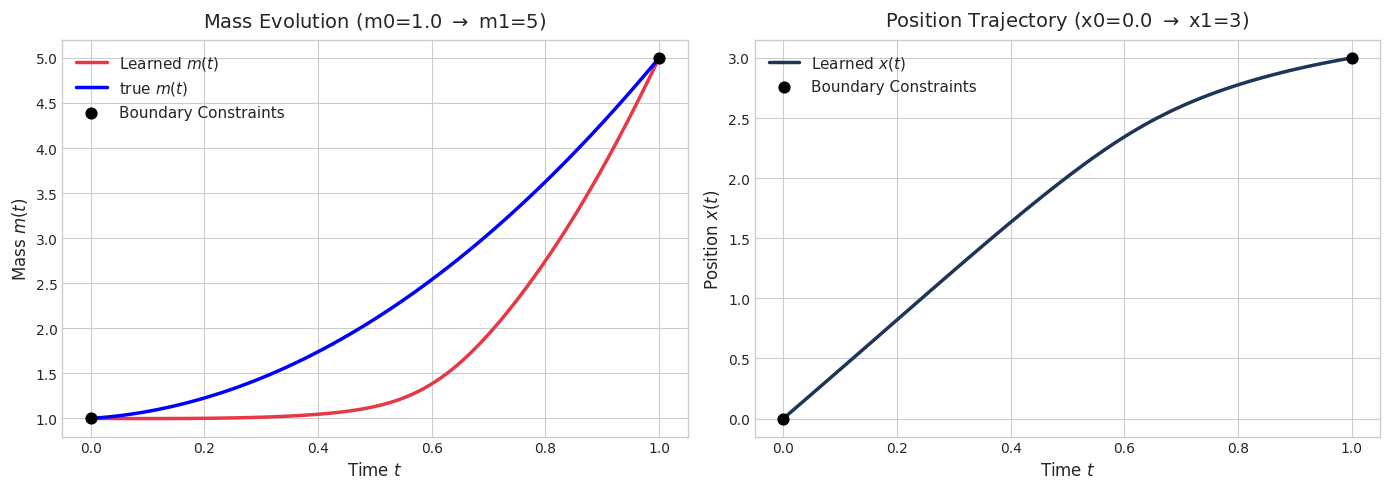

In [6]:
visualize_optimal_trajectory(path_model, d_val=3, m_val=5, device=device, delta=delta)


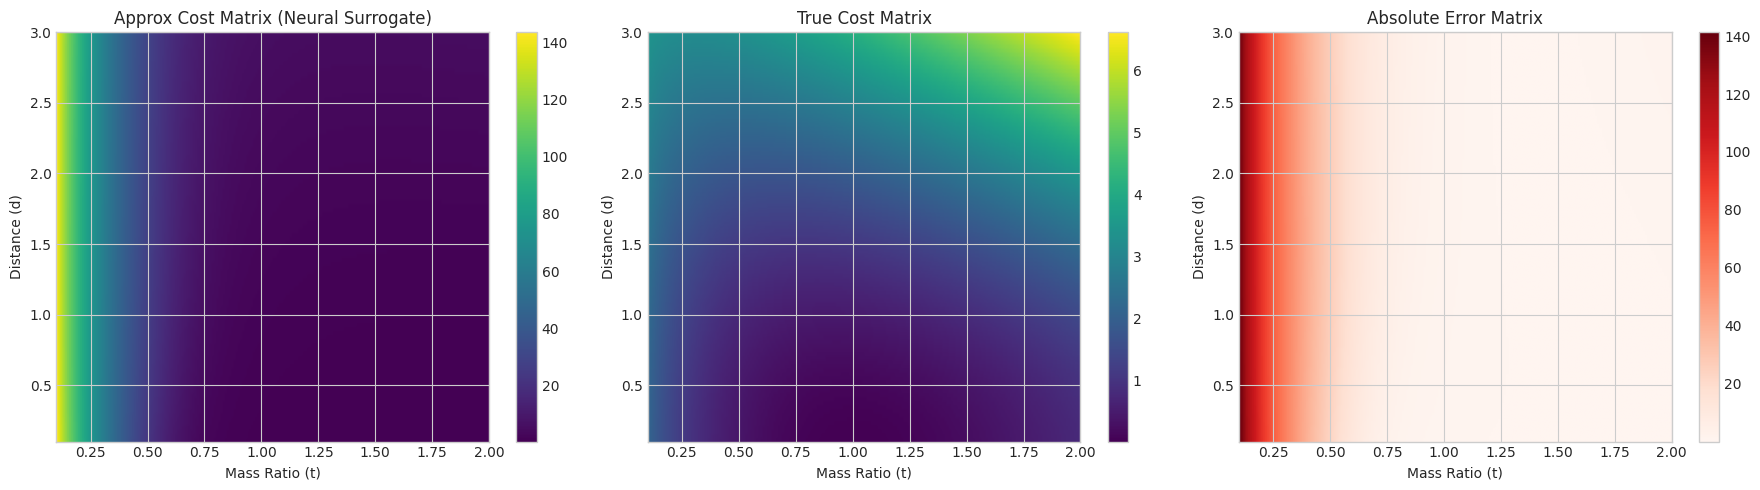

In [7]:
import matplotlib.pyplot as plt
import torch
import numpy as np


d_1d = torch.linspace(0.1, 3, 100)
t_1d = torch.linspace(0.1, 2, 200)


D, T = torch.meshgrid(d_1d, t_1d, indexing='ij')


cost_model.cpu().eval()


with torch.no_grad():
    cost_approx = cost_model(D, T).numpy()


cost_true = 2 * delta**2 * (1 + T - 2 * torch.sqrt(T) * torch.cos(torch.clamp(D / (2*delta), min=0.0, max=torch.pi/2)))
cost_true = cost_true.numpy()


fig, axes = plt.subplots(1, 3, figsize=(18, 5))


extent = [t_1d.min().item(), t_1d.max().item(), d_1d.min().item(), d_1d.max().item()]


im0 = axes[0].imshow(cost_approx, origin='lower', aspect='auto', extent=extent, cmap='viridis')
axes[0].set_title('Approx Cost Matrix (Neural Surrogate)')
axes[0].set_xlabel('Mass Ratio (t)')
axes[0].set_ylabel('Distance (d)')
fig.colorbar(im0, ax=axes[0])


im1 = axes[1].imshow(cost_true, origin='lower', aspect='auto', extent=extent, cmap='viridis')
axes[1].set_title('True Cost Matrix')
axes[1].set_xlabel('Mass Ratio (t)')
axes[1].set_ylabel('Distance (d)')
fig.colorbar(im1, ax=axes[1])


error_matrix = np.abs(cost_approx - cost_true)
im2 = axes[2].imshow(error_matrix, origin='lower', aspect='auto', extent=extent, cmap='Reds')
axes[2].set_title('Absolute Error Matrix')
axes[2].set_xlabel('Mass Ratio (t)')
axes[2].set_ylabel('Distance (d)')
fig.colorbar(im2, ax=axes[2])

plt.tight_layout()
plt.show()


## Flow matching and evaluation

In [8]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
import time as TIME
from utils import sample_from_ot_plan, Possion_Bridge, SDE, wasserstein, wasserstein_with_weights, plot_comparisions, plot_k_values


print("\n" + "="*60)
print("PART 1: Computing Multi-Time Semi-Couplings via Robust PGD")
print("="*60)

cost_model = cost_model.to(device)
# Estimate a semi-coupling for each adjacent snapshot pair.
gamma0_plans_np = []
gamma1_plans_np = []
num_intervals = len(Xs) - 1

start_t = TIME.perf_counter()
for k in range(num_intervals):
    print(f"Computing PGD coupling for interval {k} -> {k+1} ...")
    Xk_tensor = torch.tensor(Xs[k], dtype=torch.float32, device=device)
    Xk1_tensor = torch.tensor(Xs[k+1], dtype=torch.float32, device=device)


    Gamma1_opt, Gamma2_opt = compute_approx_semi_coupling_Entropic_PGD(
        Xk_tensor, Xk1_tensor, cost_model, initial_lr=1e-5, epsilon=0.001, num_iters=2000, delta=delta, use_mini_batch=True, chunk_size=2000
    )

    gamma0_plans_np.append(Gamma1_opt.cpu().detach().numpy())
    gamma1_plans_np.append(Gamma2_opt.cpu().detach().numpy())

print(f"All couplings computed in {TIME.perf_counter() - start_t:.2f}s")



PART 1: Computing Multi-Time Semi-Couplings via Robust PGD
Computing PGD coupling for interval 0 -> 1 ...

--------------------------------------------------
🚀 Running Mini-Batch Entropic PGD | Total Shape: (1429x3781) | Chunks: 2 | Max Chunk Size: 2000

   >>> Processing Chunk 1/2...
     [Chunk 1] Start optimization for shape (714x1890)
     [Chunk 1] Computing exact WFR semi-coupling as initialization...


Computing UOT plans...:   0%|          | 0/1 [00:00<?, ?it/s]

Computing UOT plans...: 100%|██████████| 1/1 [00:00<00:00,  2.77it/s]

False
true_action 1919.048822500793
     [Chunk 1] Starting Entropic PGD loop (2000 iters)...
       Step   0/2000 | LR: 0.0000 | Total Loss: 783.7291 | Physics Cost: 795.0781



/tmp/ipykernel_856162/3751281367.py:784: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Gamma1_b = torch.tensor(Gamma1_b, dtype=torch.float32, device=device)
/tmp/ipykernel_856162/3751281367.py:785: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Gamma2_b = torch.tensor(Gamma2_b, dtype=torch.float32, device=device)


...

False
true_action 492.3062282307506
     [Chunk 2] Starting Entropic PGD loop (2000 iters)...
       Step   0/2000 | LR: 0.0000 | Total Loss: 838.1121 | Physics Cost: 852.1772


       Step 200/2000 | LR: 0.0000 | Total Loss: 823.4836 | Physics Cost: 837.7648
       Step 400/2000 | LR: 0.0000 | Total Loss: 822.0097 | Physics Cost: 836.2509
       Step 600/2000 | LR: 0.0000 | Total Loss: 821.3295 | Physics Cost: 835.5497
       Step 800/2000 | LR: 0.0000 | Total Loss: 821.0221 | Physics Cost: 835.2294
       Step 1000/2000 | LR: 0.0000 | Total Loss: 820.8588 | Physics Cost: 835.0582
       Step 1200/2000 | LR: 0.0000 | Total Loss: 820.7589 | Physics Cost: 834.9532
       Step 1400/2000 | LR: 0.0000 | Total Loss: 820.6924 | Physics Cost: 834.8832
       Step 1600/2000 | LR: 0.0000 | Total Loss: 820.6436 | Physics Cost: 834.8318
       Step 1800/2000 | LR: 0.0000 | Total Loss: 820.6057 | Physics Cost: 834.7919
       Step 1999/2000 | LR: 0.0000 | Total Loss: 820.5760 | Physics Cost: 834.7607
   <<< Chunk 2 Finished | Final Loss: 820.5760 | Final Cost: 834.7607

   >>> Processing Chunk 3/3...
     [Chunk 3] Start optimization for shape (1261x1930)
     [Chunk 3] C

Computing UOT plans...: 100%|██████████| 1/1 [00:00<00:00,  2.56it/s]

False
true_action 531.8828695180233
     [Chunk 3] Starting Entropic PGD loop (2000 iters)...
       Step   0/2000 | LR: 0.0000 | Total Loss: 882.1501 | Physics Cost: 896.1927


       Step 200/2000 | LR: 0.0000 | Total Loss: 868.1127 | Physics Cost: 882.3987
       Step 400/2000 | LR: 0.0000 | Total Loss: 865.9263 | Physics Cost: 880.1732
       Step 600/2000 | LR: 0.0000 | Total Loss: 865.0278 | Physics Cost: 879.2527
       Step 800/2000 | LR: 0.0000 | Total Loss: 864.6288 | Physics Cost: 878.8406
       Step 1000/2000 | LR: 0.0000 | Total Loss: 864.3633 | Physics Cost: 878.5667
       Step 1200/2000 | LR: 0.0000 | Total Loss: 864.2253 | Physics Cost: 878.4235
       Step 1400/2000 | LR: 0.0000 | Total Loss: 864.1407 | Physics Cost: 878.3354
       Step 1600/2000 | LR: 0.0000 | Total Loss: 864.0841 | Physics Cost: 878.2764
       Step 1800/2000 | LR: 0.0000 | Total Loss: 864.0423 | Physics Cost: 878.2328
       Step 1999/2000 | LR: 0.0000 | Total Loss: 864.0101 | Physics Cost: 878.1992
   <<< Chunk 3 Finished | Final Loss: 864.0101 | Final Cost: 878.1992
All couplings computed in 591.10s


In [9]:
print("\n" + "="*60)
print("PART 2: Pre-sampling Global Training Data")
print("="*60)

# Sample endpoint pairs and mass ratios from the semi-couplings.
all_x0, all_x1, all_m0, all_m1, all_t_start, all_dt = [], [], [], [], [], []
t_train = np.arange(len(Xs)).tolist()
samples_per_interval = Xs[0].shape[0] * 5

for k in range(num_intervals):
    gamma0_plan = gamma0_plans_np[k]
    gamma1_plan = gamma1_plans_np[k]
    Xk_np = Xs[k]
    Xk1_np = Xs[k+1]


    x0_np, x1_np, idx_0, idx_1 = sample_from_ot_plan(gamma0_plan, Xk_np, Xk1_np, samples_per_interval)


    ratio = (gamma1_plan[idx_0, idx_1] / (gamma0_plan[idx_0, idx_1] + 1e-12)).reshape(-1, 1)
    m1_np = np.log(1e-8 + ratio)
    m0_np = np.zeros_like(m1_np)


    t_s = t_train[k]
    d_t = t_train[k+1] - t_train[k]

    all_x0.append(torch.tensor(x0_np, dtype=torch.float32))
    all_x1.append(torch.tensor(x1_np, dtype=torch.float32))
    all_m0.append(torch.tensor(m0_np, dtype=torch.float32))
    all_m1.append(torch.tensor(m1_np, dtype=torch.float32))
    all_t_start.append(torch.full((len(x0_np), 1), t_s, dtype=torch.float32))
    all_dt.append(torch.full((len(x0_np), 1), d_t, dtype=torch.float32))


train_x0 = torch.cat(all_x0).to(device)
train_x1 = torch.cat(all_x1).to(device)
train_m0 = torch.cat(all_m0).to(device)
train_m1 = torch.cat(all_m1).to(device)
train_t_start = torch.cat(all_t_start).to(device)
train_dt = torch.cat(all_dt).to(device)

batch_size = 256
train_dataset = TensorDataset(train_x0, train_x1, train_m0, train_m1, train_t_start, train_dt)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=True)
print(f'Global Data prepared. Total samples: {len(train_dataset)}. Batches per epoch: {len(train_loader)}')



PART 2: Pre-sampling Global Training Data


Global Data prepared. Total samples: 14290. Batches per epoch: 55


In [10]:
print("\n" + "="*60)
print("PART 3: Flow Matching Training with Surrogate Path")
print("="*60)

nu = 0.001
steps = 3000
dim = Xs[0].shape[1]


path_model.eval()
path_model.to(device)


# Train the shared velocity, score, and growth fields.
flow_model = Possion_Bridge([dim + 1, 256, 256, 256, 256, 256], nu=nu).to(device)
optimizer = torch.optim.Adam(flow_model.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=steps, eta_min=1e-5)

flow_model.train()
global_step = 0
keep_training = True

start_t = TIME.perf_counter()
while keep_training:
    for batch_idx, (b_x0, b_x1, b_m0, b_m1, b_ts, b_dt) in enumerate(train_loader):
        optimizer.zero_grad()


        relative_t = torch.rand((b_x0.shape[0], 1), device=device)
        real_t = b_dt * relative_t + b_ts


        d = torch.norm(b_x1 - b_x0, dim=-1, keepdim=True)
        m_ratio = torch.exp(b_m1 - b_m0)

        d_flat = d.squeeze(-1)
        m_ratio_flat = m_ratio.squeeze(-1)
        t_flat = relative_t.squeeze(-1).clone().requires_grad_(True)

        with torch.set_grad_enabled(True):
            m_t_1d, x_t_1d = path_model(d_flat, m_ratio_flat, t_flat)

            dm_dt_flat = torch.autograd.grad(
                outputs=m_t_1d, inputs=t_flat,
                grad_outputs=torch.ones_like(m_t_1d),
                create_graph=False, retain_graph=True
            )[0]

            dx_dt_flat = torch.autograd.grad(
                outputs=x_t_1d, inputs=t_flat,
                grad_outputs=torch.ones_like(x_t_1d),
                create_graph=False, retain_graph=False
            )[0]


        m_t_1d = m_t_1d.unsqueeze(-1).detach()
        x_t_1d = x_t_1d.unsqueeze(-1).detach()
        dm_dt = dm_dt_flat.unsqueeze(-1).detach()
        dx_dt = dx_dt_flat.unsqueeze(-1).detach()


        direction = (b_x1 - b_x0) / (d + 1e-8)
        xts_mean = b_x0 + x_t_1d * direction
        vts_samp = dx_dt * direction
        mts_samp = b_m0 + torch.log(m_t_1d + 1e-8)
        kts_samp = dm_dt / (m_t_1d + 1e-8)

        eps_samp = torch.randn_like(xts_mean)
        std = torch.sqrt(nu * relative_t * (1.0 - relative_t) + 1e-8)
        xts_samp = xts_mean + std * eps_samp


        kts_samp = kts_samp / b_dt
        vts_samp = vts_samp / b_dt


        v, s, k_out = flow_model.forward(xts_samp, real_t)

        weights = torch.exp(mts_samp)
        v_loss = torch.mean(torch.pow(v - vts_samp, 2) * weights)
        bridge_term = 2 * torch.sqrt(relative_t * (1 - relative_t)) / (nu + 1e-8)
        s_loss = torch.mean(torch.pow(bridge_term * s + eps_samp, 2) * weights)
        k_loss = torch.mean(torch.pow(k_out - kts_samp, 2) * weights)

        loss = v_loss + s_loss + k_loss
        loss.backward()
        optimizer.step()
        scheduler.step()

        global_step += 1

        if global_step % 500 == 0 or global_step == 1:
            print(f"  Step {global_step:4d}/{steps} | Total Loss: {loss.item():.4f} (v: {v_loss.item():.4f}, s: {s_loss.item():.4f}, k: {k_loss.item():.4f})")

        if global_step >= steps:
            keep_training = False
            break

print(f"Flow Matching Training completed in {TIME.perf_counter() - start_t:.2f}s")



PART 3: Flow Matching Training with Surrogate Path
  Step    1/3000 | Total Loss: 105.4370 (v: 0.3731, s: 104.0239, k: 1.0399)
  Step  500/3000 | Total Loss: 1.2624 (v: 0.0261, s: 1.2225, k: 0.0138)
  Step 1000/3000 | Total Loss: 1.3702 (v: 0.0177, s: 1.3403, k: 0.0121)
  Step 1500/3000 | Total Loss: 1.3529 (v: 0.0141, s: 1.3262, k: 0.0126)
  Step 2000/3000 | Total Loss: 1.4791 (v: 0.0144, s: 1.4510, k: 0.0137)
  Step 2500/3000 | Total Loss: 1.3768 (v: 0.0171, s: 1.3547, k: 0.0049)
  Step 3000/3000 | Total Loss: 1.5429 (v: 0.0196, s: 1.5134, k: 0.0099)
Flow Matching Training completed in 23.41s


In [11]:
print("\n" + "="*60)
print("PART 4: Global Inference and Multi-time Evaluation")
print("="*60)

flow_model.eval()
flow_model.to('cpu')

# Generate trajectories and evaluate distribution and mass errors.
simulator = SDE(flow_model, nu, mode=1, positive=False)
x_source = torch.tensor(Xs[0], dtype=torch.float32, device='cpu')

max_sample_time = len(Xs) - 1

print(f'Simulating SDE Trajectories from t=0 to t={max_sample_time}...')
start_t = TIME.perf_counter()
xs, ms, action = simulator.trajectory(
    x=x_source,
    m=torch.zeros([x_source.size(0), 1], device='cpu'),
    delta=delta,
    T=max_sample_time,
    N=max_sample_time * 100
)
print(f"Simulation completed in {TIME.perf_counter() - start_t:.2f}s\n")


mass_ratios = [Xs[k].shape[0] / Xs[0].shape[0] for k in range(len(Xs))]

for k in range(1, len(Xs)):
    print(f"--- Evaluating Time Point {k} ---")
    timestep_idx = k * 100
    if timestep_idx >= xs.shape[0]:
        timestep_idx = xs.shape[0] - 1

    x1s_gen = xs[timestep_idx, :]
    m1s_gen = np.exp(ms[timestep_idx, :])


    wa_unnorm = wasserstein(torch.Tensor(np.array(x1s_gen)), torch.tensor(Xs[k], dtype=torch.float32), power=1)
    wa_norm = wasserstein_with_weights(torch.Tensor(np.array(x1s_gen)), np.array(m1s_gen), torch.Tensor(Xs[k]), np.ones(Xs[k].shape[0]), power=1)

    target_mass_ratio = mass_ratios[k]
    RME = np.abs((np.mean(m1s_gen) - target_mass_ratio) / target_mass_ratio)

    print(f"  Wasserstein (unnormalized): {wa_unnorm:.4f}")
    print(f"  Wasserstein (normalized)  : {wa_norm:.4f}")
    print(f"  Target Mass Ratio: {target_mass_ratio:.4f} | Generated Mass Mean: {np.mean(m1s_gen):.4f}")
    print(f"  Relative Mass Error (RME) : {RME:.4f}\n")



PART 4: Global Inference and Multi-time Evaluation
Simulating SDE Trajectories from t=0 to t=2...
Continuous inference


Simulation completed in 3.73s

--- Evaluating Time Point 1 ---
  Wasserstein (unnormalized): 0.2340
  Wasserstein (normalized)  : 0.0504
  Target Mass Ratio: 2.6459 | Generated Mass Mean: 2.6113
  Relative Mass Error (RME) : 0.0131

--- Evaluating Time Point 2 ---
  Wasserstein (unnormalized): 0.2813
  Wasserstein (normalized)  : 0.0505
  Target Mass Ratio: 4.0504 | Generated Mass Mean: 3.9944
  Relative Mass Error (RME) : 0.0138



In [12]:
xs.shape


(201, 1429, 2)

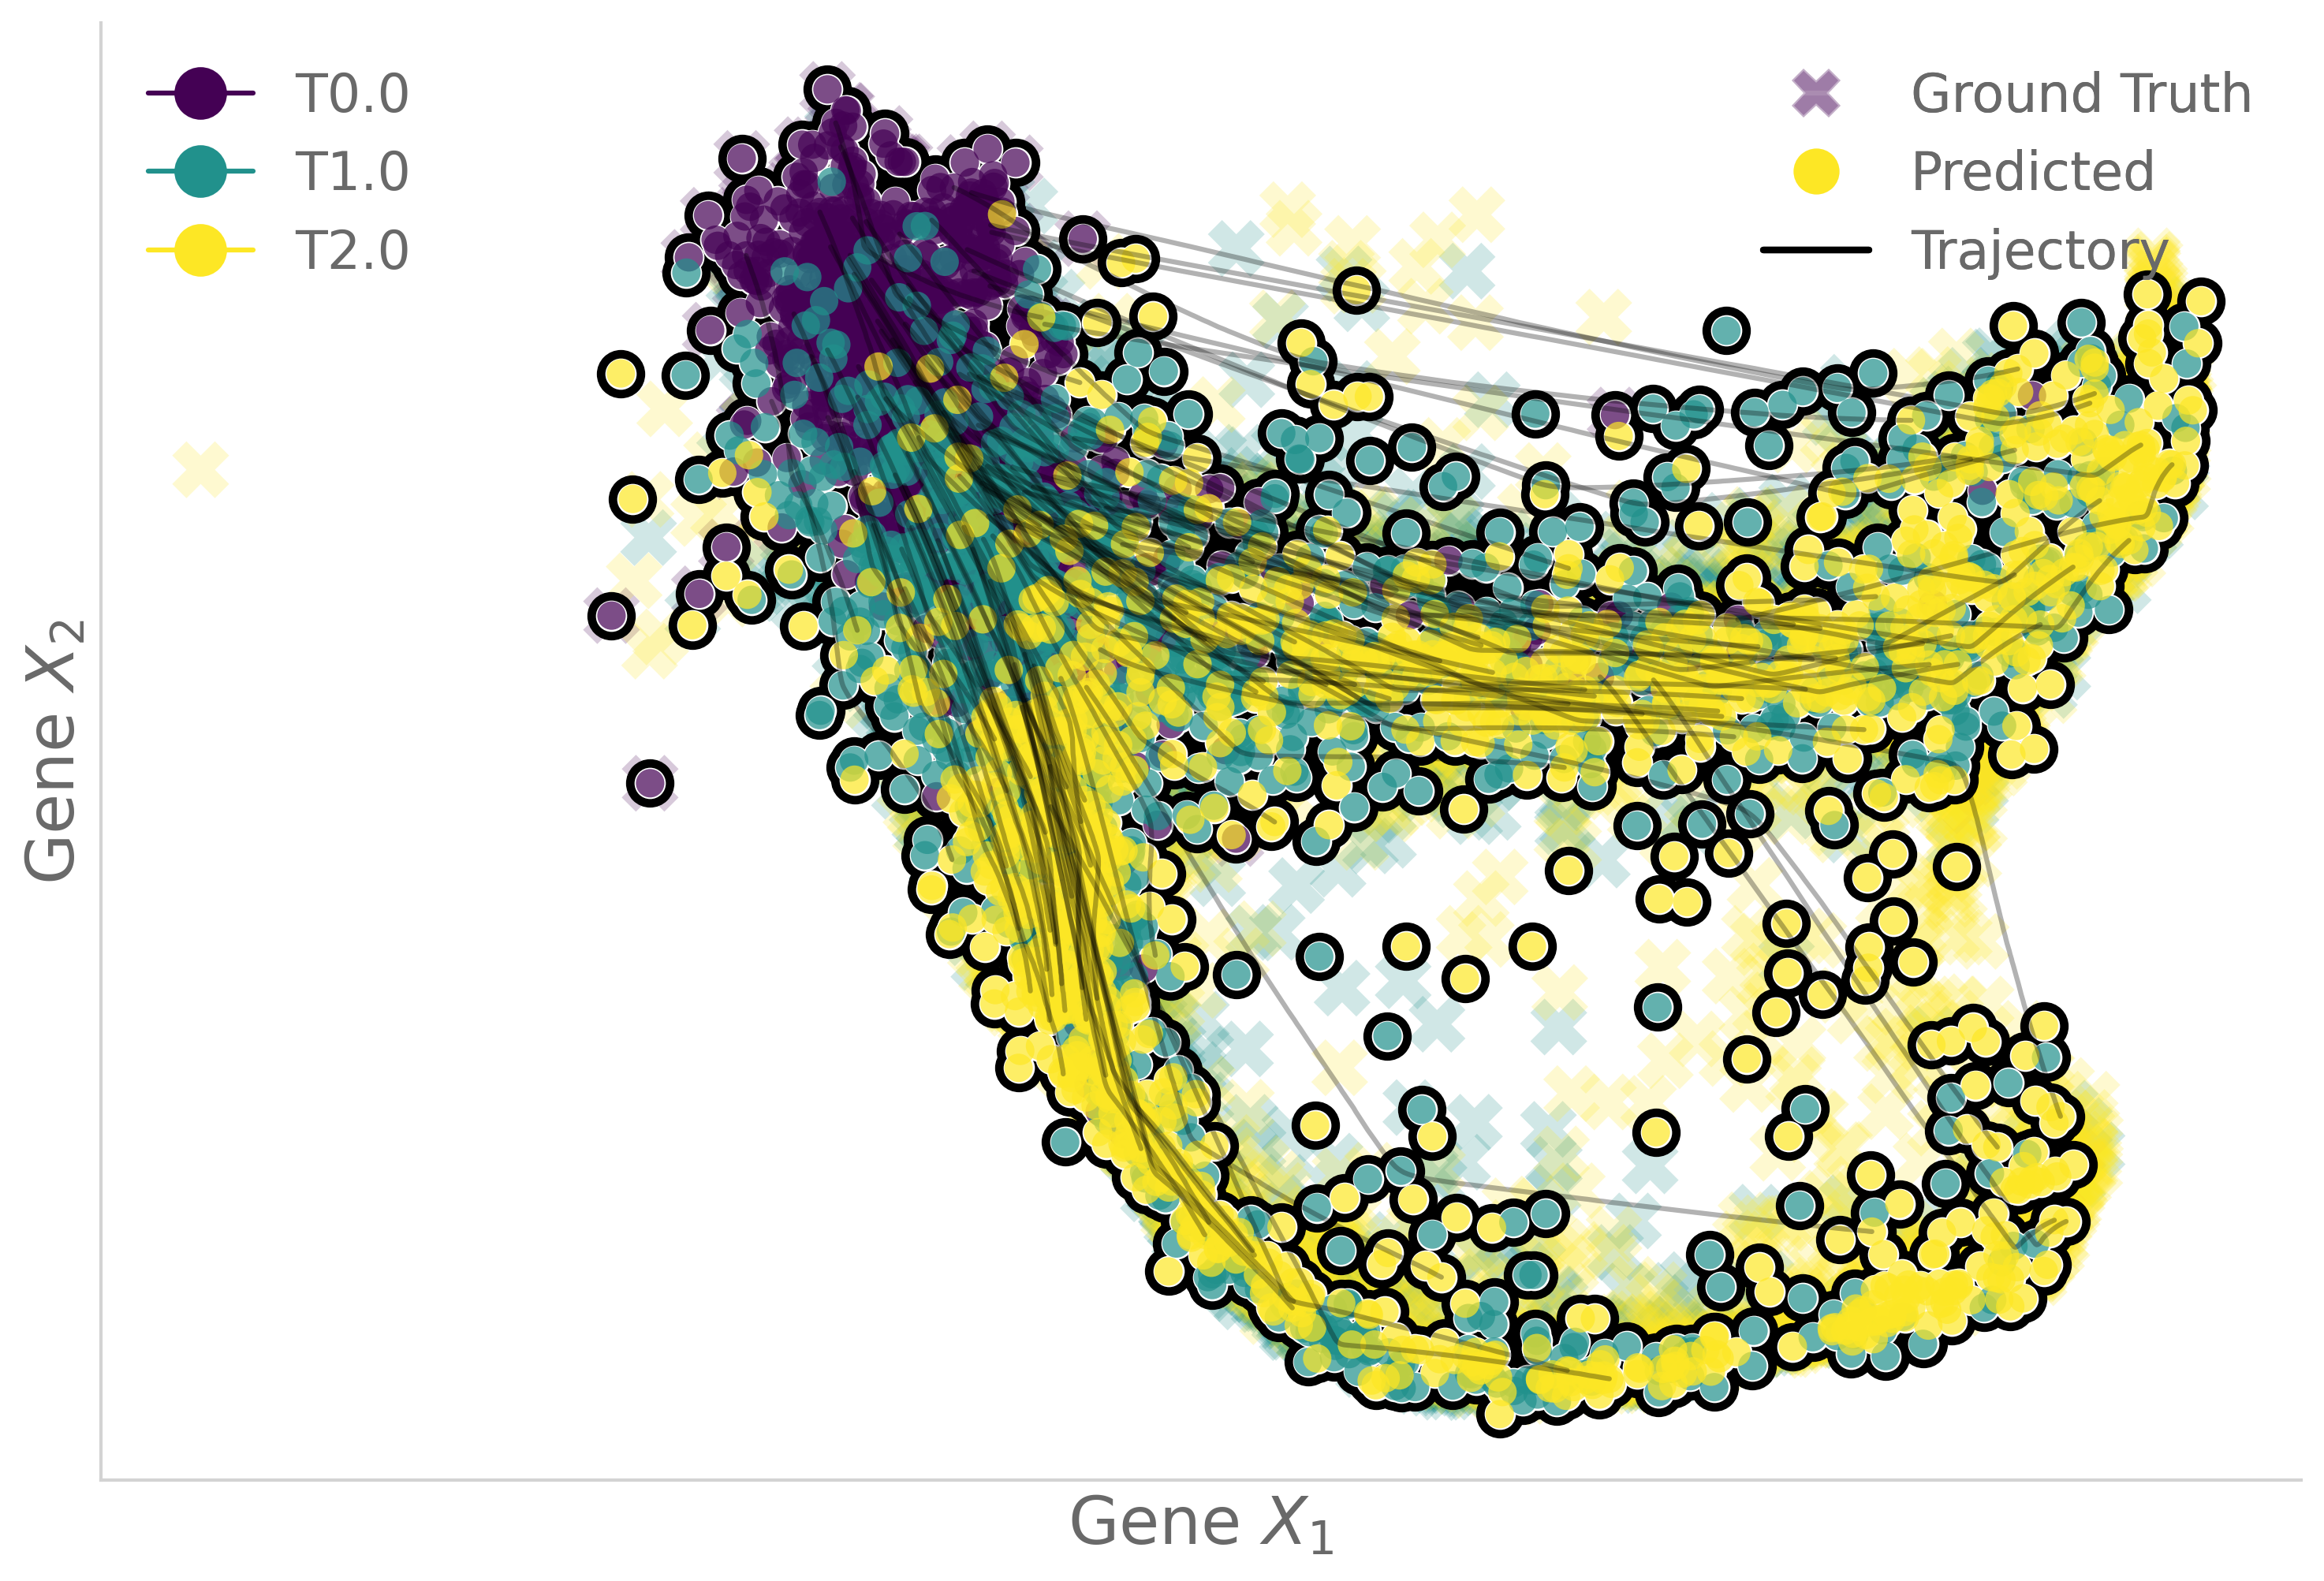

In [13]:
points = np.random.choice(xs.shape[1], size=100, replace=False)
generated = []
for time in range(len(Xs)):
    idx = time * 100
    if idx >= xs.shape[0]:
        idx = xs.shape[0] - 1
    generated.append(xs[idx, :])

plot_comparisions(data, generated, xs[:, points], path=f'comparision_multi_time_growth.png')


In [14]:
plot_k_values(Xs, flow_model, output_file=f'{data_name}'+f'_k_plot_growth_{delta}.pdf')


In [15]:
torch.save(flow_model, 'mouse_hematopoiesis_flow_model_growth_only_growth.pth')
